# Phase 3: Holling type II feeding

This phase keeps algae carrying capacity and shrimp mortality, but limits how fast each consumer can eat.

How does feeding saturation change equilibrium and oscillations?

## Units and parameter guesses

Time is in days; algae `A` is water chlorophyll-a in µg Chl-a/L; shrimp `S` is individuals/L; birds `B` is individuals. Chlorophyll represents the algae community, with *Dunaliella viridis* as the focal food species. Almost all values below are guesses to allow analysis of behavior of the model, calibration would be needed to make this better align with reality..

| Parameter | Meaning | Value | Units | Brief justification |
|---|---|---|---|---|
| `beta_A` | Algae growth rate | 0.3 | day⁻¹ | Full-blown guess |
| `K` | Algae carrying capacity | 50 | µg Chl-a/L | Full-blown guess |
| `C_A` | Shrimp clearance coefficient | 0.02 | L/(shrimp day) | Guess informed by Makridis & Vadstein, 1999 |
| `C_S` | Effective bird feeding coefficient | 0.4 | 1/(bird day) | Full-blown guess |
| `gamma_S` | Shrimp gain per chlorophyll loss | 0.2 | shrimp/(µg Chl-a) | Full-blown guess |
| `gamma_B` | Bird gain per shrimp density loss | 0.3 | bird L/shrimp | Full-blown guess |
| `delta_S` | Shrimp natural mortality | 0.03 | day⁻¹ | Full-blown guess |
| `delta_B` | Bird natural mortality | 0.12 | day⁻¹ | Full-blown guess |
| `h_A` | Inverse maximum shrimp ingestion | 0.5 | day shrimp/(micrograms Chl-a) | Full-blown guess |
| `h_S` | Inverse maximum bird density removal | 0.5 | day bird L/shrimp | Full-blown guess |

Initial conditions: `S0 = 1` shrimp/L, `A0 = 10` µg Chl-a/L, `B0 = 1` bird.

## Equations

Feeding increases with food abundance, then approaches a limit:

$$
f_A(A)=\frac{C_A A}{1+h_A C_A A},\qquad
f_S(S)=\frac{C_S S}{1+h_S C_S S}.
$$

At low food, these are close to Phase 2. At high food, they approach `1/h_A` and `1/h_S`. Larger handling parameters mean lower feeding limits. Setting both to zero recovers Phase 2.

$$
\frac{dS}{dt}=\gamma_S S f_A(A)-B f_S(S)-\delta_S S
$$

$$
\frac{dA}{dt}=\beta_A A(1-A/K)-S f_A(A)
$$

$$
\frac{dB}{dt}=\gamma_B B f_S(S)-\delta_B B.
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

beta_A = 0.3  # Guessed daily algae growth
C_A = 0.02  # More educated guess of how much algae the shrimp eat L/(shrimp day)
C_S = 0.4 # Guess of how much shrimp the birds eat
gamma_S = 0.2  # algae-to-shrimp conversion
gamma_B = 0.3 # shrimp-to-bird conversion
delta_B = 0.12 # bird death rate
K = 50.0       # algae carrying capacity
delta_S = 0.03  # shrimp mortality


h_A = 0.5  # Shrimp feeding saturation
h_S = 0.5  # Bird feeding saturation

y0 = np.array([1.0, 10.0, 1.0])  # Initial conditions: shrimp, algae, birds
T = 600.0

In [2]:
def feeding(food, attack, handling):
    return attack*food/(1 + handling*attack*food)

def rhs(t, state, ha, hs):
    S, A, B = state
    algae_eaten = S*feeding(A, C_A, ha)
    shrimp_eaten = B*feeding(S, C_S, hs)
    return np.array([
        gamma_S*algae_eaten - shrimp_eaten - delta_S*S,
        beta_A*A*(1 - A/K) - algae_eaten,
        gamma_B*shrimp_eaten - delta_B*B,
    ])

def simulate(initial, duration, ha, hs):
    initial = np.asarray(initial, dtype=float)
    if initial.shape != (3,) or np.any(initial < 0):
        raise ValueError('Initial state must contain three nonnegative populations.')
    sol = solve_ivp(lambda t, y: rhs(t, y, ha, hs), (0, duration), initial,
                    t_eval=np.linspace(0, duration, 3001), rtol=1e-8, atol=1e-10)
    if not sol.success:
        raise RuntimeError(sol.message)
    if np.min(sol.y) < -1e-7:
        raise RuntimeError('Negative numerical populations: inspect solver settings.')
    return sol

sol = simulate(y0, T, h_A, h_S)

## Equilibrium

I used a solver for these

$$
S^*=\frac{\delta_B}{C_S(\gamma_B-\delta_B h_S)}.
$$

$$
B^*=\frac{S^*(\gamma_S f_A(A^*)-\delta_S)}{f_S(S^*)}.
$$

Expanding the algae equation gives a quadratic in $A^*$:

$$
h_A C_A(A^*)^2+(1-h_A C_A K)A^*
+K\left(\frac{C_A S^*}{\beta_A}-1\right)=0.
$$


$$
A^*_+=\frac{h_A C_A K-1+
\sqrt{(1-h_A C_A K)^2+4h_A C_A K\left(1-\frac{C_A S^*}{\beta_A}\right)}}{2h_A C_A},
$$

$$
A^*_- =\frac{h_A C_A K-1-
\sqrt{(1-h_A C_A K)^2+4h_A C_A K\left(1-\frac{C_A S^*}{\beta_A}\right)}}{2h_A C_A}.
$$




In [3]:
def equilibrium(ha, hs):
    if gamma_B <= delta_B*hs: return []
    S = delta_B/(C_S*(gamma_B-delta_B*hs))
    q = ha*C_A
    coefficients = [q, 1-q*K, K*(C_A*S/beta_A-1)]
    points = []
    for root in np.roots(coefficients):
        if abs(root.imag) > 1e-8: continue
        A = root.real
        if not 0 < A < K: continue
        B = S*(gamma_S*feeding(A, C_A, ha)-delta_S)/feeding(S, C_S, hs)
        if B > 0: points.append(np.array([S, A, B]))
    return points

def jacobian(state, ha, hs):
    S, A, B = state
    fA = feeding(A, C_A, ha)
    fS = feeding(S, C_S, hs)
    dfA = C_A/(1+ha*C_A*A)**2
    dfS = C_S/(1+hs*C_S*S)**2
    return np.array([
        [gamma_S*fA-B*dfS-delta_S, gamma_S*S*dfA, -fS],
        [-fA, beta_A*(1-2*A/K)-S*dfA, 0],
        [gamma_B*B*dfS, 0, gamma_B*fS-delta_B],
    ])

points = equilibrium(h_A, h_S)
if not points:
    print('No positive equilibrium for these parameters.')
for eq in points:
    print('Equilibrium point [S, A, B]:', eq)
    assert np.allclose(rhs(0, eq, h_A, h_S), 0, atol=1e-10)
    eigenvalues = np.linalg.eigvals(jacobian(eq, h_A, h_S))
    print('Jacobian eigenvalues:', eigenvalues)
    print('Locally stable:', np.all(eigenvalues.real < 0))

Equilibrium point [S, A, B]: [ 1.25       47.16878365  0.30688509]
Jacobian eigenvalues: [-0.27304566+0.j          0.00755908+0.09760389j  0.00755908-0.09760389j]
Locally stable: False


## Feeding curves

Dashed lines show Phase 2; solid lines show Phase 3.

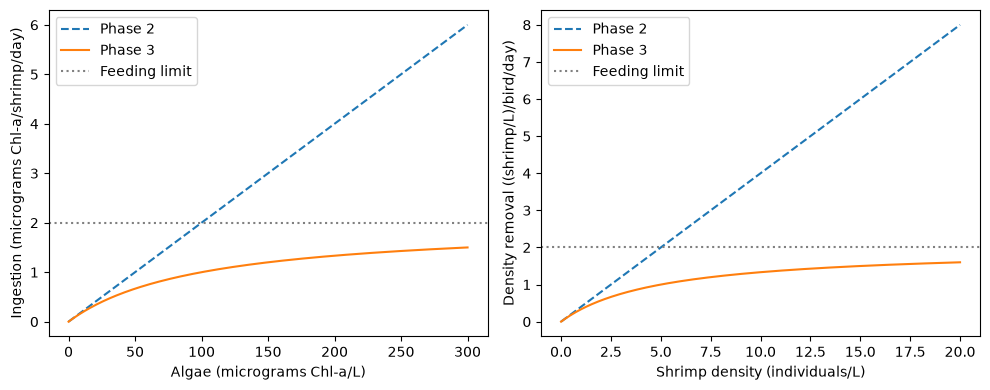

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
algae = np.linspace(0, 300, 300)
shrimp = np.linspace(0, 20, 300)

axes[0].plot(algae, C_A*algae, '--', label='Phase 2')
axes[0].plot(algae, feeding(algae, C_A, h_A), label='Phase 3')
if h_A > 0:
    axes[0].axhline(1/h_A, color='gray', linestyle=':', label='Feeding limit')
axes[0].set(xlabel='Algae (micrograms Chl-a/L)',
            ylabel='Ingestion (micrograms Chl-a/shrimp/day)')

axes[1].plot(shrimp, C_S*shrimp, '--', label='Phase 2')
axes[1].plot(shrimp, feeding(shrimp, C_S, h_S), label='Phase 3')
if h_S > 0:
    axes[1].axhline(1/h_S, color='gray', linestyle=':', label='Feeding limit')
axes[1].set(xlabel='Shrimp density (individuals/L)',
            ylabel='Density removal ((shrimp/L)/bird/day)')
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

## Change feeding saturation

Compare no saturation, shrimp saturation only, and saturation on both feeding links.

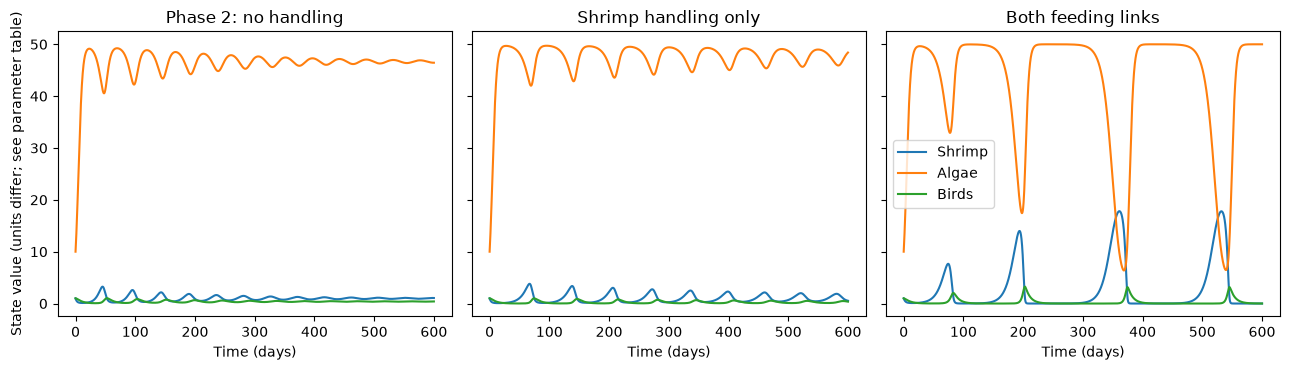

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
trials = [('Phase 2: no handling', 0, 0),
          ('Shrimp handling only', h_A, 0),
          ('Both feeding links', h_A, h_S)]
for ax, (title, ha, hs) in zip(axes, trials):
    result = simulate(y0, T, ha, hs)
    for i, label in enumerate(['Shrimp', 'Algae', 'Birds']):
        ax.plot(result.t, result.y[i], label=label)
    ax.set(title=title, xlabel='Time (days)')
axes[0].set_ylabel('State value (units differ; see parameter table)')
axes[-1].legend()
fig.tight_layout()
plt.show()

## Shrimp/algae phase portrait without birds

Set `B = 0`. The nonzero nullclines are:

$$
A=\frac{\delta_S}{C_A(\gamma_S-\delta_S h_A)},\qquad
S=\frac{\beta_A}{C_A}(1-A/K)(1+h_A C_A A).
$$

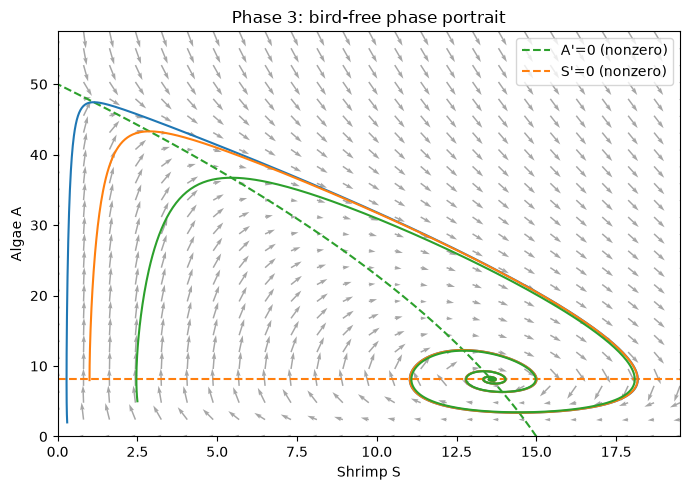

In [6]:
a_line = np.linspace(0, K, 300)
s_line = beta_A/C_A*(1-a_line/K)*(1+h_A*C_A*a_line)
Smax = max(3.0, 1.3*np.max(s_line))
Amax = 1.15*K
SS, AA = np.meshgrid(np.linspace(0, Smax, 25), np.linspace(0, Amax, 25))
dS = SS*(gamma_S*feeding(AA, C_A, h_A)-delta_S)
dA = beta_A*AA*(1-AA/K)-SS*feeding(AA, C_A, h_A)
speed = np.maximum(np.hypot(dS/Smax, dA/Amax), 1e-12)
fig, ax = plt.subplots(figsize=(7, 5))
ax.quiver(SS, AA, dS/speed, dA/speed, alpha=0.35, angles='xy')
ax.plot(s_line, a_line, '--', color='tab:green', label="A'=0 (nonzero)")
if gamma_S > delta_S*h_A:
    Astar = delta_S/(C_A*(gamma_S-delta_S*h_A))
    if Astar < Amax: ax.axhline(Astar, linestyle='--', color='tab:orange', label="S'=0 (nonzero)")
for initial in ([0.3, 2, 0], [1.0, 8, 0], [2.5, 5, 0]):
    trajectory = simulate(initial, T, h_A, h_S)
    ax.plot(trajectory.y[0], trajectory.y[1])
ax.set(xlim=(0, Smax), ylim=(0, Amax), xlabel='Shrimp S', ylabel='Algae A', title='Phase 3: bird-free phase portrait')
ax.legend()
fig.tight_layout()
plt.show()

## Sources

- [Makridis and Vadstein (1999): Food size selectivity](https://academic.oup.com/plankt/article-abstract/21/11/2191/1499662). Laboratory clearance rates inform the scale of `C_A`, not a calibrated lake-average rate.
- [Belovsky, Stumpf and Girgis (2024/2025): Artemia selective grazing](https://link.springer.com/article/10.1007/s10750-024-05719-8). Feeding experiments with *D. viridis* and other algae. The handling parameters used here remain full-blown guesses.